# Before the analysis: investigating Medicaid GLP-1 data with an explainable toolkit

**What this notebook shows:** a first pass over a real, messy public dataset (Medicaid prescription data for GLP-1 drugs such as Ozempic, Wegovy, Mounjaro and Zepbound, 2018–2025) using my [Data Investigation Toolkit](https://github.com/take2sid/data-investigation-toolkit). The toolkit reports the reason behind each decision; the point here is what a reviewer does with those reasons.

**The short version**
1. **The first pass found no key** and treated the drug code as a number. The cause: NDC codes (National Drug Code) lose their leading zeros when read as numbers, which affects nearly every row here.
2. **About a third of rows are blank by design.** CMS suppresses any cell under 11 prescriptions. Those blanks mean "1 to 10", not "unknown", so filling them with an average would be wrong.
3. **The second pass found the key CMS documents** (state + quarter + payment channel + NDC). That match is an independent check that the data was read correctly.
4. **Then the business questions:** gross Medicaid GLP-1 reimbursement grew about 17-fold from 2018 to 2025, and coverage for weight management splits the states sharply.

**Data:** CMS Medicaid State Drug Utilization Data (SDUD), GLP-1 extract compiled by Mind Lab on Kaggle ([dataset](https://www.kaggle.com/datasets/kylefengkfeng209/medicaid-glp-1-utilization-and-spending), CC BY-NC-SA 4.0). Source data is a U.S. government work.

## 1. Setup

The toolkit is a single Python file. The next cell (hidden; click to expand) writes it into the notebook's working folder so the notebook runs without internet access; the [GitHub repository](https://github.com/take2sid/data-investigation-toolkit) holds the maintained copy.

In [1]:
%%writefile data_investigation.py
"""
data_investigation: a first-pass investigation toolkit for any tabular dataset.

Load -> parse dates -> profile -> drop empty columns -> handle missing rows ->
find keys -> summarize categories and numbers -> check ranges -> flag outliers ->
pick a scaler per column from its distribution -> scale.

Author: Siddharth Turakhia. License: MIT (see LICENSE).
"""
import re
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

__version__ = "1.0.0"
__all__ = [
    "load_data", "fill_rate", "infer_dayfirst", "convert_dates", "profile",
    "constant_columns", "drop_nulls_report", "key_candidates", "find_keys",
    "categorical_counts", "numeric_summary", "auto_range_rules", "range_check",
    "iqr_outliers", "choose_scaler", "scale_columns", "run_investigation",
]

try:  # rich tables in Jupyter/Colab, plain print elsewhere
    from IPython.display import display as _display
except ImportError:  # pragma: no cover
    _display = print


def _show(obj, show):
    if show:
        _display(obj)


# ---------------------------------------------------------------- load and dates
def load_data(path, show=True, **read_csv_kwargs):
    """Read a CSV and trim spaces from column names and every text value."""
    df = pd.read_csv(path, skipinitialspace=True, **read_csv_kwargs)
    df.columns = df.columns.str.strip()
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = df[col].str.strip()
    if show:
        _display(df.shape)
        _display(df.head())
    return df


def fill_rate(df):
    """Percent filled and percent missing per column."""
    return pd.DataFrame({"Fill_Rate_%": df.notna().mean() * 100,
                         "Missing_%": df.isna().mean() * 100})


def infer_dayfirst(sample):
    """Work out day/month order from numeric dates. Returns (True/False/None, reason)."""
    parts = sample.str.extract(r"^\s*(\d{1,2})[/\-. ](\d{1,2})[/\-. ](\d{2,4})").dropna().astype(int)
    if parts.empty:
        return None, "month as text or year first: order not needed"
    first_big, second_big = (parts[0] > 12).any(), (parts[1] > 12).any()
    if first_big and not second_big:
        return True, "a first number above 12: day first"
    if second_big and not first_big:
        return False, "a second number above 12: month first"
    if first_big and second_big:
        return None, "MIXED orders in this column: check by hand"
    return None, "every date ambiguous (all numbers 12 or under): default used"


def convert_dates(df, threshold=0.90, sample_size=1000, force=None, skip=None,
                  dayfirst="auto", default_dayfirst=False, show=True):
    """Find date columns by testing values, infer day/month order, convert, and report."""
    df = df.copy()
    force, skip = force or [], skip or []
    report = []
    for col in df.select_dtypes(include=["object", "string"]).columns:
        if col in skip:
            continue
        sample = df[col].dropna().astype(str).str.strip()
        sample = sample.sample(min(sample_size, len(sample)), random_state=1)
        if sample.str.fullmatch(r"\d+").all() and col not in force:
            report.append((col, 0.0, "", "skipped: numbers only"))
            continue
        if dayfirst == "auto":
            guess, how = infer_dayfirst(sample)
            use_dayfirst = default_dayfirst if guess is None else guess
        else:
            use_dayfirst, how = (dayfirst == "day first"), "set by user"
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            parsed = pd.to_datetime(sample, errors="coerce", format="mixed", dayfirst=use_dayfirst)
        rate = parsed.notna().mean()
        if rate >= threshold or col in force:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                df[col] = pd.to_datetime(df[col], errors="coerce", format="mixed", dayfirst=use_dayfirst)
            report.append((col, round(rate * 100, 1), how, "converted"))
        else:
            report.append((col, round(rate * 100, 1), "", "left as text"))
    _show(pd.DataFrame(report, columns=["Column", "Parse_%", "Day/month order", "Action"]), show)
    return df


# ---------------------------------------------------------------- profile and cleaning
def profile(df, high_missing=20, max_categories=20):
    """One row per column: dtype, % missing, unique count, an example, and a FLAG."""
    n = len(df)
    out = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_%": (df.isna().mean() * 100).round(2),
        "unique": df.nunique(dropna=True),
        "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
    })

    def flag(row):
        if row["unique"] == 0:
            return "all blank: drop"
        if row["unique"] == 1:
            return "constant: drop"
        if row["unique"] == n and not row["dtype"].startswith("float"):
            return "ID-like: possible key"
        if row["missing_%"] > high_missing:
            return f"over {high_missing}% blank: decide fill or drop"
        if row["dtype"] in ("object", "string", "str") and row["unique"] <= max_categories:
            return "category"
        return ""

    out["flag"] = out.apply(flag, axis=1)
    return out


def constant_columns(df, show=True):
    """Drop columns with one value in every row, or blank in every row."""
    counts = df.nunique(dropna=False)
    const = counts[counts <= 1].index.tolist()
    if show:
        print(f"Dropping {len(const)} constant column(s): {const}" if const
              else "No constant columns; nothing dropped.")
    return df.drop(columns=const)


def drop_nulls_report(df, threshold=10, show=True):
    """Drop rows with any blank; report losses, the columns behind them, and recoverable rows."""
    df_clean = df.dropna()
    n_before, n_after = len(df), len(df_clean)
    pct = round((n_before - n_after) / n_before * 100, 2) if n_before else 0.0
    if show:
        print(f"Original rows: {n_before:,}\nRows kept:     {n_after:,}\n"
              f"Rows dropped:  {n_before - n_after:,} ({pct}%)")
        missing = df.isna().sum()
        missing = missing[missing > 0].sort_values(ascending=False)
        if len(missing):
            _display(missing.to_frame("Missing_rows"))
            na = df.isna()
            bad = na[na.any(axis=1)]
            _display(bad.sum(axis=1).value_counts().sort_index()
                     .rename_axis("Blanks_in_row").to_frame("Rows"))
            _display(bad.apply(lambda r: " + ".join(r.index[r]), axis=1).value_counts()
                     .rename_axis("Blank_columns").to_frame("Rows"))
            single = bad[bad.sum(axis=1) == 1].idxmax(axis=1).value_counts()
            if len(single):
                _display(single.rename_axis("Column").to_frame("Rows_recovered"))
        print(f"\nMore than {threshold}% of rows dropped: consider filling instead."
              if pct > threshold else "\nProceed with analysis.")
    return df_clean


# ---------------------------------------------------------------- keys
def key_candidates(df, force_keep=None, force_drop=None, show=True):
    """Classify columns as possible key parts; returns the columns to EXCLUDE from find_keys."""
    force_keep, force_drop = force_keep or [], force_drop or []
    id_name = re.compile(r"(^|_)(id|code|key|no|num|npi|zip)($|_)", re.IGNORECASE)
    rows = []
    for c in df.columns:
        s = df[c]
        if c in force_drop:
            keep, why = False, "forced out"
        elif c in force_keep:
            keep, why = True, "forced in"
        elif not pd.api.types.is_numeric_dtype(s):
            keep, why = True, "text/date"
        elif pd.api.types.is_float_dtype(s):
            keep, why = False, "decimal = measure"
        elif id_name.search(c):
            keep, why = True, "ID-like name"
        else:
            widths = s.dropna().abs().astype("int64").astype(str).str.len()
            if widths.nunique() == 1 and widths.iloc[0] >= 4:
                keep, why = True, f"fixed width ({widths.iloc[0]} digits)"
            else:
                keep, why = False, "integer measure"
        rows.append({"Column": c, "Key_candidate": keep, "Reason": why})
    table = pd.DataFrame(rows)
    _show(table, show)
    return table.loc[~table.Key_candidate, "Column"].tolist()


def find_keys(df, max_cols=4, exclude=None, sample_rows=200_000, block_col=None, max_results=5):
    """Smallest column combinations that uniquely identify every row (screen, then confirm)."""
    exclude = exclude or []
    n = len(df)
    cols = [c for c in df.columns if c not in exclude and df[c].notna().all()]
    card = df[cols].nunique()
    if n > sample_rows:
        if block_col:
            blocks = df[block_col].drop_duplicates().sample(frac=1, random_state=1)
            sizes = df[block_col].value_counts()
            chosen = blocks[sizes[blocks].cumsum().values <= sample_rows]
            screen = df[df[block_col].isin(chosen)]
        else:
            screen = df.sample(sample_rows, random_state=1)
    else:
        screen = df
    found = []
    for k in range(1, max_cols + 1):
        for combo in combinations(cols, k):
            combo = list(combo)
            if np.prod(card[combo].values, dtype=float) < n:
                continue
            if screen.duplicated(subset=combo).any():
                continue
            if not df.duplicated(subset=combo).any():
                found.append({"Key_columns": " + ".join(combo), "Columns": k})
                if len(found) >= max_results:
                    return pd.DataFrame(found)
        if found:
            break
    if not found:
        print(f"No key found with up to {max_cols} columns.")
    return pd.DataFrame(found)


# ---------------------------------------------------------------- summaries and checks
def categorical_counts(df, show=False):
    """One combined table of Column, Value, Count, Percent for every text column."""
    out = []
    for col in df.select_dtypes(include=["object", "category", "string"]).columns:
        t = df.groupby(col, dropna=False).size().reset_index(name="Count")
        t["Percent"] = (t["Count"] / len(df) * 100).round(2)
        t = t.rename(columns={col: "Value"})
        t.insert(0, "Column", col)
        out.append(t)
        if show:
            print(f"\n--- {col} ---")
            _display(t)
    return pd.concat(out, ignore_index=True) if out else pd.DataFrame(
        columns=["Column", "Value", "Count", "Percent"])


def numeric_summary(df, show=True):
    """describe() plus unique, skew, kurtosis, % zeros and % negatives per numeric column."""
    num = df.select_dtypes(include="number")
    s = num.describe().T
    s["unique"] = num.nunique()
    s["skew"] = num.skew()
    s["kurtosis"] = num.kurt()
    s["zeros_%"] = num.eq(0).mean() * 100
    s["negatives_%"] = num.lt(0).mean() * 100
    s = s.round(2)
    _show(s, show)
    return s


AUTO_RULES = {
    ("unit", "qty", "quantity", "count", "sales", "price", "amount", "revenue", "cost"): (0, None),
    ("pct", "percent", "rate"): (0, 100),
    ("age",): (0, 120),
}


def auto_range_rules(df, auto_rules=None):
    """Infer allowed limits from column names (e.g. quantities and prices cannot be negative)."""
    auto_rules = auto_rules or AUTO_RULES
    rules = {}
    for col in df.select_dtypes(include="number").columns:
        # Match whole name parts, so 'Discount_pct' matches 'pct', not 'count'.
        tokens = [t for t in re.split(r"[^a-z]+", col.lower()) if t]
        for keys, limits in auto_rules.items():
            if any(t.startswith(k) for t in tokens for k in keys):
                rules[col] = limits
                break
    return rules


def range_check(df, rules, show=True):
    """Count values outside allowed limits; rules = {column: (low, high)}, None = no limit."""
    rows = []
    for col, (lo, hi) in rules.items():
        if col not in df.columns:
            print(f"Skipped '{col}': not in this dataset.")
            continue
        s = df[col]
        below = int((s < lo).sum()) if lo is not None else 0
        above = int((s > hi).sum()) if hi is not None else 0
        rows.append({"Column": col, "Min_allowed": lo, "Max_allowed": hi, "Below": below,
                     "Above": above, "Bad_%": round((below + above) / len(df) * 100, 2)})
    report = pd.DataFrame(rows)
    _show(report, show)
    return report


def iqr_outliers(df, k=1.5, show=True):
    """Tukey fences per numeric column: values beyond Q1 - k*IQR or Q3 + k*IQR."""
    num = df.select_dtypes(include="number")
    rows = []
    for col in num.columns:
        q1, q3 = num[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        low, high = q1 - k * iqr, q3 + k * iqr
        n_low, n_high = int((num[col] < low).sum()), int((num[col] > high).sum())
        rows.append({"Column": col, "Q1": q1, "Q3": q3, "IQR": iqr, "Lower_fence": low,
                     "Upper_fence": high, "Below": n_low, "Above": n_high,
                     "Outlier_%": round((n_low + n_high) / len(num) * 100, 2)})
    report = pd.DataFrame(rows).set_index("Column")
    _show(report, show)
    return report


# ---------------------------------------------------------------- scaling
def choose_scaler(summary, outliers, outlier_limit=1.0, skew_limit=1.0, exclude=None, show=True):
    """Pick a scaler per numeric column from its distribution, with the reason.
    exclude = columns never to scale (e.g. numeric IDs)."""
    exclude = exclude or []
    rows = []
    for col in [c for c in summary.index if c not in exclude]:
        sk, out_pct, mn = summary.loc[col, "skew"], outliers.loc[col, "Outlier_%"], summary.loc[col, "min"]
        if summary.loc[col, "unique"] <= 2:
            pick, why = "None", "binary flag: scaling adds nothing"
        elif out_pct > outlier_limit:
            pick, why = "RobustScaler", f"{out_pct}% outliers would distort MinMax and Standard"
        elif abs(sk) > skew_limit and mn >= 0:
            pick, why = "log1p, then MinMaxScaler", f"skew {sk}: log pulls in the long tail first"
        elif abs(sk) <= 0.5:
            pick, why = "StandardScaler", f"skew {sk}: close to symmetric, z-scores read cleanly"
        else:
            pick, why = "MinMaxScaler", f"skew {sk}, no outlier problem: safe to squeeze into 0-1"
        rows.append({"Column": col, "Scaler": pick, "Why": why})
    table = pd.DataFrame(rows).set_index("Column")
    _show(table, show)
    return table


def scale_columns(df, scaler_choice, always_minmax=True):
    """Add <col>_minmax (optional) plus the distribution-chosen scaled column where it differs."""
    cols = scaler_choice.index.tolist()
    out = df.copy()
    if always_minmax and cols:
        out[[c + "_minmax" for c in cols]] = MinMaxScaler().fit_transform(df[cols])
    for c in cols:
        pick = scaler_choice.loc[c, "Scaler"]
        if pick == "StandardScaler":
            out[c + "_standard"] = StandardScaler().fit_transform(df[[c]]).ravel()
        elif pick == "RobustScaler":
            out[c + "_robust"] = RobustScaler().fit_transform(df[[c]]).ravel()
        elif pick == "log1p, then MinMaxScaler":
            out[c + "_log_minmax"] = MinMaxScaler().fit_transform(np.log1p(df[[c]])).ravel()
    return out


# ---------------------------------------------------------------- one call
def run_investigation(source, dayfirst="auto", range_rules=None, null_threshold=10,
                      always_minmax=True, show=False):
    """Run the whole pipeline on a CSV path or a DataFrame. Returns a dict of results."""
    df = load_data(source, show=show) if isinstance(source, str) else source.copy()
    df = convert_dates(df, dayfirst=dayfirst, show=show)
    prof = profile(df)
    df = constant_columns(df, show=show)
    clean = drop_nulls_report(df, threshold=null_threshold, show=show)
    not_keys = key_candidates(clean, show=False)
    keys = find_keys(clean, exclude=not_keys)
    id_cols = [c for c in clean.select_dtypes(include="number").columns if c not in not_keys]
    summary = numeric_summary(clean, show=show)
    rules = {**auto_range_rules(clean), **(range_rules or {})}
    ranges = range_check(clean, rules, show=show)
    outliers = iqr_outliers(clean, show=show)
    scalers = choose_scaler(summary, outliers, exclude=id_cols, show=show)
    scaled = scale_columns(clean, scalers, always_minmax=always_minmax)
    return {"data": df, "profile": prof, "clean": clean, "keys": keys,
            "categories": categorical_counts(clean), "numeric_summary": summary,
            "range_check": ranges, "outliers": outliers, "scalers": scalers, "scaled": scaled}

Overwriting data_investigation.py


In [2]:
import glob, pandas as pd, matplotlib.pyplot as plt
from data_investigation import run_investigation, load_data, profile, drop_nulls_report, key_candidates, iqr_outliers
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)

def find_file(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(f"data/{name}")
    return hits[0]

NDC_FILE = find_file("glp1_medicaid_ndc_quarterly.csv")
NDC_FILE

'data/glp1_medicaid_ndc_quarterly.csv'

## 2. First pass: run the toolkit as-is

I start with the file at CMS's own reporting grain (one row per state, quarter, payment channel and drug package) and run everything with default settings. No cleaning first: the point is to see what the toolkit flags.

In [3]:
first = run_investigation(NDC_FILE)
first["profile"]

No key found with up to 4 columns.


,dtype,missing_%,unique,example,flag
state,str,0.00,53,AK,
state_name,str,0.00,53,Alaska,
is_national_total,bool,0.00,2,False,
year,int64,0.00,8,2018,
quarter,int64,0.00,4,1,
period,datetime64[us],0.00,32,2018-01-01 00:00:00,
quarter_start_date,datetime64[us],0.00,32,2018-01-01 00:00:00,
utilization_type,str,0.00,2,FFSU,category
payment_channel,str,0.00,2,Fee-for-service,category
ndc,int64,0.00,100,310652004,


**What it flagged:** seven numeric columns are about 33% blank, and the profile asks me to decide whether to fill or drop. Before deciding, two more results matter.

In [4]:
print("Key found:", not first["keys"].empty)
first["scalers"].loc[["ndc"]]

Key found: False


,Scaler,Why
Column,,
ndc,RobustScaler,1.92% outliers would distort MinMax and Standard


**Two warning signs:**
- **No key.** Every row of a reporting file should be identifiable by some combination of columns. Not finding one usually means a column was read wrongly.
- **The NDC was treated as a measure and given a scaler.** An NDC is an identifier, and scaling an identifier is meaningless.

**Why:** pandas read the NDC as a number. In the raw file it is an 11-digit code with leading zeros (for example `00169406012`, Victoza). As a number it becomes `169406012`, so codes no longer have a fixed width, and the toolkit's ID check (fixed width or an ID-like name) correctly declined to call it an ID.

In [5]:
raw = pd.read_csv(NDC_FILE, dtype=str, usecols=["ndc"])
print("NDCs starting with 0:", f"{raw.ndc.str.startswith('0').mean():.0%}")
print("Lengths as text:", raw.ndc.str.len().unique(), "| as numbers:", sorted(first["data"].ndc.astype(str).str.len().unique()))

NDCs starting with 0: 99%


Lengths as text: [11] | as numbers: [np.int64(7), np.int64(8), np.int64(9), np.int64(11)]


## 3. Three decisions before the second pass

| Decision | Why |
|---|---|
| **Read NDC, labeler and product codes as text** | They are identifiers. Leading zeros carry meaning, and a mangled NDC will not join to any other drug file. |
| **Remove CMS's national rows (state = "XX")** | They are totals of the state rows. Keeping both double-counts every prescription. |
| **Do not fill the suppressed blanks** | CMS blanks any cell under 11 prescriptions, so the true value is 1 to 10, not "missing at random". An average fill would invent volume. The toolkit's warning ("more than 10% of rows dropped: consider filling") is the right prompt; here the right answer is to keep the rows, flag them, and analyze measured rows with that limit stated. |

In [6]:
df = load_data(NDC_FILE, show=False, dtype={"ndc": str, "labeler_code": str, "product_code": str})
states = df[~df.is_national_total].copy()
print(f"National rows removed: {len(df) - len(states):,}")
print(f"Rows suppressed by CMS: {states.suppression_used.mean():.0%}")
states.groupby("state").suppression_used.mean().sort_values(ascending=False).head(5).round(2).rename("share_suppressed")

National rows removed: 2,555
Rows suppressed by CMS: 34%


state
ND    0.52
WY    0.52
AR    0.46
NJ    0.45
DC    0.44
Name: share_suppressed, dtype: float64

Suppression is not spread evenly: small states lose about half their rows, large states far fewer. **Any state ranking built on measured rows alone will understate small states.** That caveat travels with every chart below.

## 4. Second pass

In [7]:
second = run_investigation(states)
second["keys"]

,Key_columns,Columns
0,state + period + utilization_type + ndc,4
1,state + period + payment_channel + ndc,4
2,state + quarter_start_date + utilization_type ...,4
3,state + quarter_start_date + payment_channel +...,4
4,state_name + period + utilization_type + ndc,4


**The key is now state + period + payment channel (utilization type) + NDC.** That is exactly the grain CMS and the dataset author document. Finding it independently confirms the file was read correctly, which is the purpose of the key search: it checks the reading as well as describing the data.

In [8]:
second["scalers"]

,Scaler,Why
Column,,
quarter,StandardScaler,"skew -0.05: close to symmetric, z-scores read ..."
package_size,StandardScaler,"skew 0.48: close to symmetric, z-scores read c..."
units_reimbursed,RobustScaler,13.84% outliers would distort MinMax and Standard
number_of_prescriptions,RobustScaler,14.52% outliers would distort MinMax and Standard
total_amount_reimbursed,RobustScaler,14.39% outliers would distort MinMax and Standard
medicaid_amount_reimbursed,RobustScaler,14.53% outliers would distort MinMax and Standard
non_medicaid_amount_reimbursed,RobustScaler,15.05% outliers would distort MinMax and Standard
reimbursement_per_prescription,RobustScaler,3.51% outliers would distort MinMax and Standard
units_per_prescription,RobustScaler,14.11% outliers would distort MinMax and Standard


**Reading the scaler choices:** about 14% of rows sit above the outlier fence for the volume and dollar columns. These are not errors. They are the largest states and brands (California, New York, Ozempic) in a heavily right-skewed market. RobustScaler, which uses the median and the middle 50% of values, is the sound choice: it keeps the big states from compressing everyone else.

**Where the fences do find errors:** reimbursement per prescription.

In [9]:
m = second["clean"]
high = m[m.reimbursement_per_prescription > 3000]
print(f"Rows over $3,000 per prescription: {len(high)}")
print(high.groupby(["state", "payment_channel"]).size().rename("rows"))
print("Already flagged by the dataset author:", int(high.cost_per_rx_outlier.sum()))

Rows over $3,000 per prescription: 71
state  payment_channel
NY     Managed care       69
UT     Managed care        2
Name: rows, dtype: int64
Already flagged by the dataset author: 71


The upper fence on reimbursement per prescription is about \$1,467. Above \$3,000 the rows are all New York and Utah managed-care records, which the dataset author also flagged as source anomalies. **The toolkit's fences and the author's manual review agree**, and these rows are kept but excluded from price comparisons.

## 5. What the clean data says

Two questions a commercial or market-access team would ask first. One caveat applies to both: **these are gross reimbursements, before manufacturer rebates.** GLP-1 rebates are large and confidential, so net cost to Medicaid is materially lower than these figures.

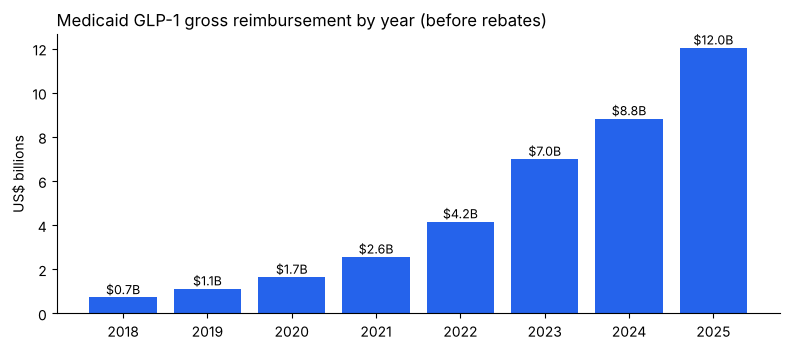

Growth 2018 to 2025: 17x | gross per prescription: $674 to $1,070


In [10]:
yr = states.groupby("year").agg(prescriptions=("number_of_prescriptions", "sum"),
                                gross=("total_amount_reimbursed", "sum"))
yr["gross_per_rx"] = yr.gross / yr.prescriptions
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(yr.index, yr.gross / 1e9, color="#2563eb")
for x, v in zip(yr.index, yr.gross / 1e9):
    ax.text(x, v + 0.15, f"${v:.1f}B", ha="center", fontsize=9)
ax.set_title("Medicaid GLP-1 gross reimbursement by year (before rebates)", loc="left")
ax.set_ylabel("US$ billions"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
print(f"Growth 2018 to 2025: {yr.gross.loc[2025] / yr.gross.loc[2018]:.0f}x | gross per prescription: "
      f"${yr.gross_per_rx.loc[2018]:,.0f} to ${yr.gross_per_rx.loc[2025]:,.0f}")

**About 17-fold growth in seven years**, driven mostly by volume (prescriptions up about 10-fold) and partly by mix: gross reimbursement per prescription rose from about \$674 to about \$1,070 as newer, higher-priced brands took share.

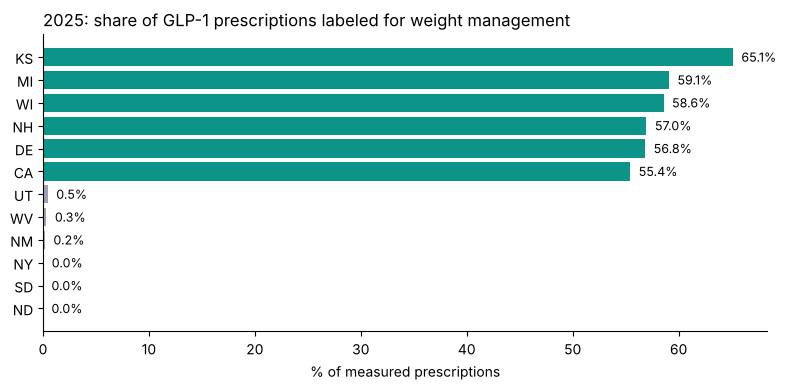

In [11]:
s25 = (states[states.year == 2025]
       .groupby(["state", "primary_indication"]).number_of_prescriptions.sum().unstack(fill_value=0))
s25["weight_mgmt_share"] = s25["Chronic weight management"] / s25.sum(axis=1) * 100
rank = s25.weight_mgmt_share.sort_values()
show = pd.concat([rank.head(6), rank.tail(6)])
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(show.index, show.values, color=["#9ca3af"] * 6 + ["#0d9488"] * 6)
for y, v in enumerate(show.values):
    ax.text(v + 0.8, y, f"{v:.1f}%", va="center", fontsize=9)
ax.set_title("2025: share of GLP-1 prescriptions labeled for weight management", loc="left")
ax.set_xlabel("% of measured prescriptions"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Same drugs, same federal program, opposite coverage decisions.** In Kansas about two-thirds of measured GLP-1 prescriptions in 2025 were weight-management brands (Wegovy, Zepbound, Saxenda); in New York the share was close to zero.

Two cautions from the investigation above:
- **North and South Dakota read 0%, but every weight-management row there was suppressed.** Their true share is unknown and small, not zero.
- **Labels are FDA indications, not reasons for use.** Ozempic prescribed off-label for weight loss counts as diabetes here.

For a commercial or access team, this is a coverage-policy map: where state formulary decisions, not prescriber demand, set the ceiling on uptake.

## 6. Takeaways

- **Read identifiers as text.** One dtype choice decided whether the file had a key at all, and whether an NDC would join to any other drug file.
- **Know why data is missing before handling it.** Suppressed is not missing at random; the honest move is to keep, flag and state the limit.
- **Let the key search check the reading.** Matching CMS's documented grain was the evidence that the second pass was right.
- **Separate errors from big numbers.** About 14% of rows past the fence were real large states; the 71 rows above \$3,000 per prescription were real anomalies.
- **Gross is not net.** Every dollar figure here is before rebates.

*Analysis design, scaling rules and testing are mine; the toolkit's packaging and documentation were done with AI assistance (Claude), with every output reviewed by me. Feedback welcome.*